# Node2Vec: node embeddings from random walks

Node2Vec ([Grover and Leskovec, 2016](https://arxiv.org/abs/1607.00653)) learns a vector for every node of a graph without using any node features: two nodes get similar vectors when they often appear close to each other on random walks. It works in two steps.

1. **Biased random walks.** From every node, we sample a few walks of fixed length. After a step `t -> v`, the next node `x` is a neighbor of `v`, chosen with an unnormalized weight of `1/p` if `x` is `t` itself (going back), `1` if `x` is also a neighbor of `t` (staying close to `t`), and `1/q` otherwise (moving away). The **return parameter** `p` therefore controls how often a walk steps back, and the **in-out parameter** `q` interpolates between a breadth-first exploration of the neighborhood (`q > 1`, BFS-like) and a depth-first one that moves away from the start (`q < 1`, DFS-like). With `p = q = 1` the walks are uniform, as in DeepWalk.
2. **Skip-gram with negative sampling.** Nodes that appear within a few steps of each other on a walk are trained to have a large dot product, and random pairs of nodes (the *negative samples*) a small one. This is the word2vec objective, with walks as sentences and nodes as words.

In this tutorial, we train Node2Vec with mlx-graphs on the Cora citation graph, and evaluate the embeddings on node classification and link prediction. We then look at the effect of `p` and `q`, at sampling the walks on the GPU or the CPU, and we finally compare mlx-graphs with PyTorch Geometric (PyG).

**Requirements.** mlx-graphs samples the walks with the `mlx_cluster` package (version 0.1.2 or later, which requires `mlx>=0.32`). The evaluation uses scikit-learn, and the comparison with PyG needs PyTorch and PyG:

`pip install mlx_cluster scikit-learn pandas matplotlib torch torch_geometric`

![Node2Vec pipeline: on the Cora graph (PlanetoidDataset, edges only), pos_sample draws biased random walks (weight 1/p back, 1 near t, 1/q away) cut into windows of 10 nodes and neg_sample draws random windows; a 2,708 x 128 Embedding is trained with the skip-gram loss and Adam, evaluated by logistic-regression node classification and link prediction, then walk biases, GPU and CPU sampling, and mlx-graphs on the GPU vs PyG on the CPU are compared](../../_static/tutorials/node2vec.svg)

In [1]:
import time

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np

from mlx_graphs.algorithms import Node2Vec
from mlx_graphs.datasets import PlanetoidDataset

SEED = 0
mx.random.seed(SEED)
np.random.seed(SEED)  # the Node2Vec dataloader shuffles the nodes with NumPy

## The dataset

We use Cora, from the [Planetoid](https://github.com/kimiyoung/planetoid) collection of citation networks: 2,708 scientific papers, linked by 10,556 directed edges (5,278 citations, stored in both directions). Each paper belongs to one of 7 topics. Node2Vec only uses the edges: the bag-of-words node features and the labels are used below to evaluate the embeddings, never to train them.

In [2]:
dataset = PlanetoidDataset("Cora")
graph = dataset[0]
num_nodes = graph.num_nodes
print(graph)

labels = np.array(graph.node_labels)
train_mask, test_mask = np.array(graph.train_mask), np.array(graph.test_mask)
print(f"{num_nodes} nodes, {graph.num_edges} edges, {labels.max() + 1} classes")
print(f"mean degree {graph.num_edges / num_nodes:.2f}")
print(f"{train_mask.sum()} training nodes, {test_mask.sum()} test nodes")

Loading cora data ... Done
GraphData(
	edge_index(shape=(2, 10556), int32)
	node_features(shape=(2708, 1433), float32)
	node_labels(shape=(2708,), int32)
	train_mask(shape=(2708,), bool)
	val_mask(shape=(2708,), bool)
	test_mask(shape=(2708,), bool))
2708 nodes, 10556 edges, 7 classes
mean degree 3.90
140 training nodes, 1000 test nodes


## The model

`Node2Vec` holds one embedding per node, the graph in CSR format for the walks, and the sampling and loss functions. Its main hyperparameters are:

- `embedding_dim`: the size of each embedding vector.
- `walk_length`: the number of nodes in each random walk.
- `context_size`: the size of the sliding window over a walk. Each walk of `walk_length` nodes is cut into `walk_length - context_size + 1` windows of `context_size` nodes, and the first node of each window is trained to be close to the other nodes of the window. Cutting long walks into windows reuses every sampled walk many times.
- `walks_per_node`: the number of walks started from each node.
- `num_negative_samples`: the number of negative (random) windows per positive window.
- `p` and `q`: the return and in-out parameters of the walks (see above).
- `use_gpu`: whether to sample the walks on the GPU or on the CPU.

We use the values of PyG's [Node2Vec example](https://github.com/pyg-team/pytorch_geometric/blob/master/examples/node2vec.py), with uniform walks for now.

In [3]:
EMBEDDING_DIM = 128
WALK_LENGTH = 20
CONTEXT_SIZE = 10
WALKS_PER_NODE = 10
NUM_NEGATIVE_SAMPLES = 1
BATCH_SIZE = 128
LEARNING_RATE = 0.01
NUM_EPOCHS = 10


def make_model(p=1.0, q=1.0, edge_index=graph.edge_index, use_gpu=True, **kwargs):
    config = dict(
        embedding_dim=EMBEDDING_DIM,
        walk_length=WALK_LENGTH,
        context_size=CONTEXT_SIZE,
        walks_per_node=WALKS_PER_NODE,
        num_negative_samples=NUM_NEGATIVE_SAMPLES,
    )
    config.update(kwargs)
    return Node2Vec(
        edge_index=edge_index, num_nodes=num_nodes, p=p, q=q, use_gpu=use_gpu, **config
    )


model = make_model()
model

Node2Vec(
  (embedding): Embedding(2708, 128)
)

### What a batch of walks looks like

`pos_sample` samples `walks_per_node` walks from each node of a batch and cuts them into windows. Here we start from node 0 only: the 10 walks of 20 nodes give 10 x 11 = 110 windows of 10 nodes. The windows are grouped by position (the first window of every walk, then the second window of every walk, and so on), so rows 0, 10, 20, ... are the successive windows of the first walk. Each one starts one step further along the walk.

In [4]:
windows = model.pos_sample(mx.array([0]))
print("positive windows:", windows.shape)
print(windows[::WALKS_PER_NODE])

positive windows: (110, 10)
array([[0, 2582, 1166, ..., 633, 0, 633],
       [2582, 1166, 2582, ..., 0, 633, 1866],
       [1166, 2582, 1166, ..., 633, 1866, 633],
       ...,
       [0, 633, 1866, ..., 1701, 1857, 1701],
       [633, 1866, 633, ..., 1857, 1701, 729],
       [1866, 633, 1866, ..., 1701, 729, 2534]], dtype=int64)


Every step of a walk follows an edge of the graph. The negative windows from `neg_sample` have the same shape, but after the start node the nodes are drawn uniformly at random:

In [5]:
negatives = model.neg_sample(mx.array([0]))
print("negative windows:", negatives.shape)
print(negatives[:3])

negative windows: (110, 10)
array([[0, 1502, 2502, ..., 841, 187, 1915],
       [0, 213, 1266, ..., 1695, 1606, 2132],
       [0, 154, 554, ..., 1873, 2121, 1552]], dtype=int32)


`model.dataloader(batch_size)` shuffles the nodes and yields one `(positive, negative)` pair of window arrays per batch of start nodes:

In [6]:
pos, neg = next(model.dataloader(batch_size=BATCH_SIZE))
print(
    f"one batch of {BATCH_SIZE} start nodes: positive {pos.shape}, negative {neg.shape}"
)

one batch of 128 start nodes: positive (14080, 10), negative (14080, 10)


## Training

`model.loss(pos, neg)` is the skip-gram loss: for each window, it takes the embedding `z_u` of the first node and the embeddings `z_v` of the other nodes, and averages `-log(sigmoid(z_u . z_v))` over the positive windows and `-log(1 - sigmoid(z_u . z_v))` over the negative ones. We minimize it with Adam. One epoch samples new walks from every node.

`bias_correction=True` gives the update rule of `torch.optim.Adam`, which we use in the comparison with PyG below.

In [7]:
def train(model, num_epochs=NUM_EPOCHS, verbose=False):
    """Trains the model and returns the seconds and the mean loss of each epoch."""
    optimizer = optim.Adam(learning_rate=LEARNING_RATE, bias_correction=True)
    loss_and_grad = nn.value_and_grad(model, model.loss)
    epoch_times, losses = [], []
    for epoch in range(num_epochs):
        start, total, num_batches = time.perf_counter(), 0.0, 0
        for pos, neg in model.dataloader(batch_size=BATCH_SIZE):
            loss, grads = loss_and_grad(pos, neg)
            optimizer.update(model, grads)
            mx.eval(model.parameters(), optimizer.state, loss)
            total, num_batches = total + loss.item(), num_batches + 1
        epoch_times.append(time.perf_counter() - start)
        losses.append(total / num_batches)
        if verbose:
            print(
                f"epoch {epoch + 1:2d}  loss {losses[-1]:.4f}  {epoch_times[-1]:.2f} s"
            )
    return epoch_times, losses


epoch_times, losses = train(model, verbose=True)

epoch  1  loss 1.1673  0.14 s
epoch  2  loss 0.8798  0.13 s
epoch  3  loss 0.8464  0.13 s
epoch  4  loss 0.8373  0.13 s
epoch  5  loss 0.8348  0.13 s
epoch  6  loss 0.8338  0.13 s
epoch  7  loss 0.8303  0.13 s
epoch  8  loss 0.8299  0.13 s
epoch  9  loss 0.8285  0.13 s
epoch 10  loss 0.8290  0.13 s


## Evaluating the embeddings

A common way to evaluate node embeddings is to train a linear classifier on top of them. We fit a logistic regression on the embeddings of Cora's 140 training nodes, and measure its accuracy on the 1,000 test nodes. As a reference, the same classifier on the bag-of-words features of the papers, which Node2Vec never sees, is also shown.

In [8]:
from sklearn.linear_model import LogisticRegression


def test_accuracy(features):
    clf = LogisticRegression(max_iter=1000)
    clf.fit(features[train_mask], labels[train_mask])
    return clf.score(features[test_mask], labels[test_mask])


embeddings = np.array(model.embedding.weight)
print(f"Node2Vec embeddings: test accuracy {test_accuracy(embeddings):.3f}")
features = np.array(graph.node_features)
print(f"bag-of-words features: test accuracy {test_accuracy(features):.3f}")

Node2Vec embeddings: test accuracy 0.703
bag-of-words features: test accuracy 0.576


Node2Vec learns the topics of the papers from the citation graph alone. The accuracy of a single run changes by about a point from one seed to the next, so we use several seeds when comparing settings below.

### A 2-D view of the embeddings

t-SNE projects the 128-dimensional embeddings onto a plane while keeping close points close. Each panel shows all nodes in gray, and the nodes of one class in blue. If the embeddings capture the topics, the nodes of a class form a few dense groups instead of being spread over the whole plane.

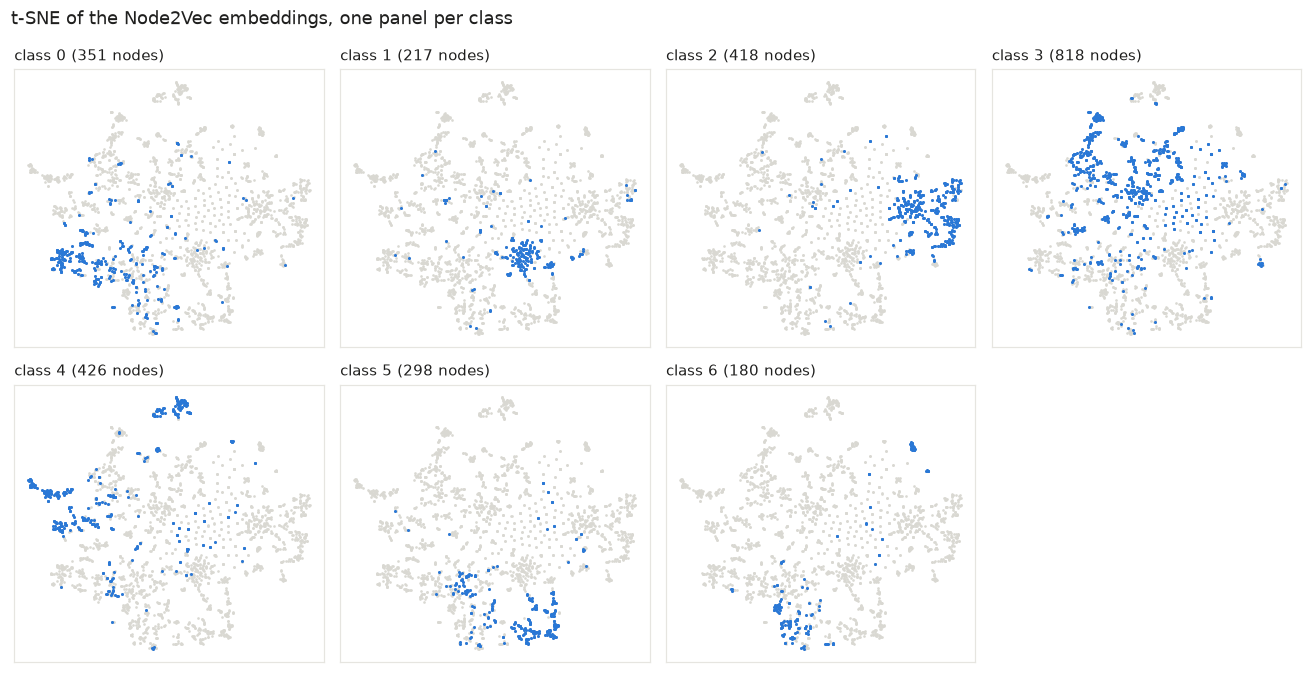

In [9]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

INK, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6a64", "#e6e5e0", "#d9d8d2"
MLX_COLOR, PYG_COLOR = "#2a78d6", "#eb6834"

projection = TSNE(n_components=2, init="pca", random_state=SEED).fit_transform(
    embeddings
)

num_classes = labels.max() + 1
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for c, ax in enumerate(axes.flat):
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color(GRID)
    if c == num_classes:
        ax.set_visible(False)
        continue
    ax.scatter(*projection.T, s=3, color=SURFACE, linewidths=0)
    members = labels == c
    ax.scatter(*projection[members].T, s=4, color=MLX_COLOR, linewidths=0)
    ax.set_title(
        f"class {c} ({members.sum()} nodes)", loc="left", color=INK, fontsize=10
    )
fig.suptitle(
    "t-SNE of the Node2Vec embeddings, one panel per class",
    x=0.01,
    ha="left",
    color=INK,
)
fig.tight_layout()
plt.show()

### Link prediction

The embeddings can also predict missing edges. `RandomLinkSplit` hides 10% of the citations (the test edges) and samples as many unconnected node pairs (the negative edges). We train a new model on the remaining graph, score each pair by the dot product of its two embeddings (the quantity the skip-gram loss pushes up for nodes close on the walks), and measure the ROC AUC with `mlx_graphs.metrics`. We don't tune anything here, so the validation split is not used.

In [10]:
from mlx_graphs.metrics import average_precision_score, roc_auc_score
from mlx_graphs.transforms import RandomLinkSplit

mx.random.seed(SEED)
np.random.seed(SEED)
split = RandomLinkSplit(num_val=0.05, num_test=0.1, is_undirected=True)
train_graph, _, test_graph = split(graph)
print(f"training graph: {train_graph.num_edges} edges")
print(f"test pairs: {test_graph.edge_label_index.shape[1]} (half of them are edges)")

link_model = make_model(edge_index=train_graph.edge_index)
train(link_model)

z = link_model.embedding.weight
src, dst = test_graph.edge_label_index
scores = (z[src] * z[dst]).sum(axis=-1)
auc = roc_auc_score(test_graph.edge_label, scores)
ap = average_precision_score(test_graph.edge_label, scores)
print(f"test ROC AUC {auc:.3f}, average precision {ap:.3f}")

training graph: 8976 edges
test pairs: 1054 (half of them are edges)
test ROC AUC 0.894, average precision 0.928


## The effect of `p` and `q`

We now compare three kinds of walks, changing only `q`:

- **uniform** (`p = 1, q = 1`): every neighbor is equally likely.
- **BFS-like** (`p = 1, q = 4`): moving away from the previous node is 4 times less likely, so walks stay in the neighborhood of their start.
- **DFS-like** (`p = 1, q = 0.25`): moving away is 4 times more likely, so walks travel further.

To see the difference, we sample one walk of 20 nodes from every node and measure the number of distinct nodes it visits, how often it steps straight back to the node it came from, and the shortest-path distance (in hops) between its first and last nodes.

In [11]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

WALK_SETTINGS = {
    "uniform (p=1, q=1)": (1.0, 1.0),
    "BFS-like (p=1, q=4)": (1.0, 4.0),
    "DFS-like (p=1, q=0.25)": (1.0, 0.25),
}

src_np, dst_np = np.array(graph.edge_index)
adjacency = csr_matrix((np.ones(src_np.size), (src_np, dst_np)), shape=(num_nodes,) * 2)
hops = shortest_path(adjacency, unweighted=True)


def sample_walks(p, q, walks_per_node=1):
    """Full walks of WALK_LENGTH nodes, rebuilt from the windows of pos_sample."""
    model = make_model(p, q, walks_per_node=walks_per_node, context_size=WALK_LENGTH)
    return np.array(model.pos_sample(mx.arange(num_nodes)))


walk_stats = {}
for name, (p, q) in WALK_SETTINGS.items():
    mx.random.seed(SEED)
    walks = sample_walks(p, q)
    walk_stats[name] = {
        "distinct nodes": np.mean([len(set(w)) for w in walks]),
        "steps back (%)": 100 * np.mean(walks[:, 2:] == walks[:, :-2]),
        "hops start to end": np.mean(hops[walks[:, 0], walks[:, -1]]),
    }
    print(f"{name:<23}", walks[0])

uniform (p=1, q=1)      [   0 1862 2582 1862  926 1862 1701 1052 1701   13 1701 1334 1950 1947
  310 1272 1945  310 1272 1945]
BFS-like (p=1, q=4)     [   0 1862    0 2582    0 1862    0 2582 1166 1986 2007 1986  476 1986
 1995  745  553 1995 1583 1013]
DFS-like (p=1, q=0.25)  [   0 1862 1701 1100  598 2138  548 1523 2449 1523  548  843 2339  843
 2339 1191 2241  500 2241 1957]


Setting `context_size` equal to `walk_length` gives one window per walk, so the windows are the full walks. The first walk of each setting, from node 0, is printed above. We then train one model per setting and seed, and evaluate it as before.

In [12]:
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
PQ_SEEDS = [0, 1, 2]

pq_accuracy = {}
for name, (p, q) in WALK_SETTINGS.items():
    pq_accuracy[name] = []
    for seed in PQ_SEEDS:
        mx.random.seed(seed)
        np.random.seed(seed)
        pq_model = make_model(p, q)
        train(pq_model)
        pq_accuracy[name].append(test_accuracy(np.array(pq_model.embedding.weight)))

pq_table = pd.DataFrame(walk_stats).T.round(2)
pq_table["test accuracy"] = [
    f"{np.mean(a):.3f} ± {np.std(a, ddof=1):.3f}" for a in pq_accuracy.values()
]
pq_table

,distinct nodes,steps back (%),hops start to end,test accuracy
"uniform (p=1, q=1)",12.28,29.37,3.78,0.706 ± 0.007
"BFS-like (p=1, q=4)",9.07,44.58,2.81,0.678 ± 0.010
"DFS-like (p=1, q=0.25)",14.54,18.51,4.27,0.724 ± 0.006


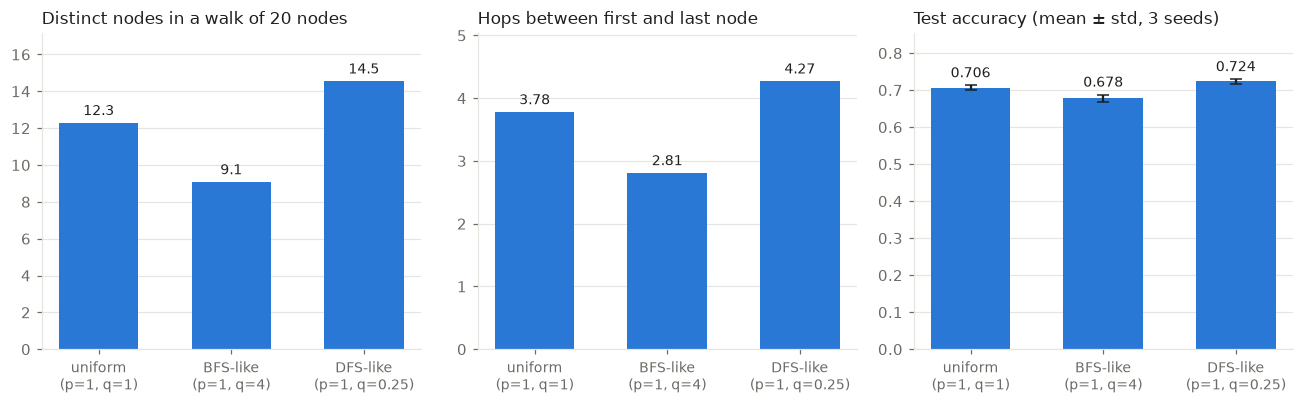

In [13]:
def style_axis(ax):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)


def label_bars(ax, bars, values, errors, fmt):
    """Writes each value above its bar, or above its error bar."""
    errors = errors if errors is not None else [0] * len(values)
    for bar, value, error in zip(bars, values, errors):
        ax.annotate(
            format(value, fmt),
            (bar.get_x() + bar.get_width() / 2, value + error),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=INK,
            fontsize=9,
        )


names = list(WALK_SETTINGS)
short_names = [n.replace(" (", "\n(") for n in names]
x = np.arange(len(names))
panels = [
    (
        "Distinct nodes in a walk of 20 nodes",
        [walk_stats[n]["distinct nodes"] for n in names],
        None,
        ".1f",
    ),
    (
        "Hops between first and last node",
        [walk_stats[n]["hops start to end"] for n in names],
        None,
        ".2f",
    ),
    (
        "Test accuracy (mean ± std, 3 seeds)",
        [np.mean(pq_accuracy[n]) for n in names],
        [np.std(pq_accuracy[n], ddof=1) for n in names],
        ".3f",
    ),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (title, values, errors, fmt) in zip(axes, panels):
    bars = ax.bar(x, values, 0.6, color=MLX_COLOR, yerr=errors, ecolor=INK, capsize=4)
    label_bars(ax, bars, values, errors, fmt)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xticks(x, short_names, fontsize=9)
    ax.set_ylim(0, max(values) * 1.18)
    style_axis(ax)
fig.tight_layout()
plt.show()

The walk statistics behave as the parameters suggest. With `q = 4`, the walks step back much more often, visit fewer distinct nodes and end closer to their start: they describe the immediate neighborhood of each node. With `q = 0.25`, they visit more nodes and travel further.

On Cora, the walks that travel further give the best test accuracy here, and the BFS-like walks the lowest. Papers on the same topic form groups larger than a node's direct neighbors, so a wider context helps to recognize them. Other graphs and tasks can favor the other end: the best `p` and `q` depend on the data, and should be chosen on a validation set.

## Sampling the walks on the GPU or the CPU

`use_gpu` selects the device of the walk sampler only: `random_walk` for uniform walks, and `rejection_sampling` for biased ones. The embedding lookups, the loss, the gradients and the optimizer updates run on MLX's default device, which is the GPU on Apple silicon.

We first time the sampling of the positive windows of every node (27,080 walks of 20 nodes) on each device. The timer reports the median over 10 calls, after 2 warm-up calls that compile the Metal kernels.

In [14]:
import statistics


def benchmark(fn, sync, warmup=2, repeats=10):
    """Median wall-clock time of fn() in ms. sync(out) waits for the result."""
    for _ in range(warmup):
        sync(fn())
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        sync(fn())
        times.append(time.perf_counter() - start)
    return statistics.median(times) * 1000


all_nodes = mx.arange(num_nodes)
device_rows = {}
for name, (p, q) in [
    ("uniform (p=1, q=1)", (1.0, 1.0)),
    ("biased (p=1, q=0.25)", (1.0, 0.25)),
]:
    device_rows[name] = {}
    for device in ["GPU", "CPU"]:
        sampler = make_model(p, q, use_gpu=device == "GPU")
        ms = benchmark(lambda: sampler.pos_sample(all_nodes), sync=mx.eval)
        device_rows[name][f"{device} walks (ms)"] = round(ms, 1)
device_table = pd.DataFrame(device_rows).T
device_table["GPU speedup"] = (
    device_table["CPU walks (ms)"] / device_table["GPU walks (ms)"]
).map("{:.1f}x".format)
device_table

,GPU walks (ms),CPU walks (ms),GPU speedup
"uniform (p=1, q=1)",0.6,2.6,4.3x
"biased (p=1, q=0.25)",2.3,17.5,7.6x


The device changes where the walks are sampled, not which walks are sampled: with the same seed, the CPU and the GPU return the same walks.

In [15]:
for name, (p, q) in [("uniform", (1.0, 1.0)), ("biased", (1.0, 0.25))]:
    walks = {}
    for device in ["GPU", "CPU"]:
        mx.random.seed(SEED)
        walks[device] = make_model(p, q, use_gpu=device == "GPU").pos_sample(all_nodes)
    print(
        f"{name:<8} walks identical on GPU and CPU: {mx.array_equal(*walks.values())}"
    )

uniform  walks identical on GPU and CPU: True
biased   walks identical on GPU and CPU: True


Sampling is only part of an epoch. To compare whole epochs, we also run training entirely on the CPU, by changing MLX's default device as well, and time 3 epochs in each configuration.

In [16]:
training_rows = {}
for label, use_gpu, device in [
    ("walks on GPU, training on GPU", True, mx.gpu),
    ("walks on CPU, training on GPU", False, mx.gpu),
    ("walks on CPU, training on CPU", False, mx.cpu),
]:
    mx.set_default_device(device)
    try:
        mx.random.seed(SEED)
        times, _ = train(make_model(use_gpu=use_gpu), num_epochs=3)
    finally:
        mx.set_default_device(mx.gpu)
    training_rows[label] = {"s/epoch": round(statistics.median(times), 3)}
pd.DataFrame(training_rows).T

,s/epoch
"walks on GPU, training on GPU",0.136
"walks on CPU, training on GPU",0.138
"walks on CPU, training on CPU",1.228


The GPU samples walks faster than the CPU, and the gap is larger for biased walks, whose rejection sampling does more work per step (see the speedups in the first table). Over a whole epoch, however, the walks are a small part of the time when the rest of the training runs on the GPU: sampling them on the CPU makes an epoch only slightly slower. Most of the gain comes from running the training itself on the GPU, as the last row of the second table shows.

## mlx-graphs vs PyG

PyG has the same `Node2Vec` model, with the same arguments, sampling and loss, so we can train both on the same graph with the same hyperparameters and compare three things:

1. **Walk sampling**: the time to sample the positive windows of every node with each library's `pos_sample`, with walks of 80 nodes (the length used in the Node2Vec paper), and a check that the walks follow the edges of the graph.
2. **Training**: the time per epoch of each library's training loop, which includes the sampling, the loss, the gradients and the optimizer updates.
3. **Embedding quality**: the logistic-regression test accuracy, so that the speeds are compared at equal quality.

Each library runs on its usual device on a Mac: mlx-graphs on the GPU, and PyG on the CPU. PyG's walk sampler has no GPU version on macOS, and the many small operations of Node2Vec training are faster on PyTorch's CPU backend than on MPS.

**PyG's walk sampler.** PyG's `Node2Vec` samples its walks with the `random_walk` operator of the optional `pyg-lib` package, which supports uniform walks only (`p = q = 1`) and raises an error for biased walks. When `pyg-lib` is not installed, `Node2Vec` refuses to start. In that case, the cell below registers a short PyTorch implementation of the same operator, with the same inputs, outputs and uniform-only restriction, so that PyG's `Node2Vec` runs unchanged on top of it. The printed line tells which sampler is used: timings with the fallback measure this PyTorch code, not `pyg-lib`.

In [17]:
import warnings

# With recent PyTorch versions, importing PyG warns that torch.jit.script is deprecated
warnings.filterwarnings("ignore", message=".*torch.jit.script.* is deprecated")

In [18]:
import platform
from importlib.metadata import version

import torch
import torch_geometric.nn.models.node2vec as pyg_node2vec_module
from torch_geometric.nn import Node2Vec as PyGNode2Vec
from torch_geometric.typing import WITH_PYG_LIB

if not WITH_PYG_LIB:

    @torch.library.custom_op("pyg::random_walk", mutates_args=())
    def random_walk(
        rowptr: torch.Tensor,
        col: torch.Tensor,
        seed: torch.Tensor,
        walk_length: int,
        p: float,
        q: float,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Uniform random walks (pyg-lib's pyg::random_walk, in plain PyTorch)."""
        if p != 1.0 or q != 1.0:
            raise RuntimeError("Uniform sampling required for now")
        degree = rowptr[1:] - rowptr[:-1]
        node, nodes, edges = seed, [seed], []
        rand = torch.rand(walk_length, seed.numel())
        for step in range(walk_length):
            deg = degree[node]
            edge = rowptr[node] + (rand[step] * deg).long()
            has_neighbors = deg > 0  # nodes without neighbors stay in place
            node = torch.where(
                has_neighbors, col[edge.clamp(max=col.numel() - 1)], node
            )
            nodes.append(node)
            edges.append(torch.where(has_neighbors, edge, -1))
        return torch.stack(nodes, dim=1), torch.stack(edges, dim=1)

    pyg_node2vec_module.WITH_PYG_LIB = True  # Node2Vec checks this flag at init

PYG_SAMPLER = "pyg-lib" if WITH_PYG_LIB else "PyTorch fallback"
print(f"{platform.platform()}, {platform.processor()}")
for package in ["mlx", "mlx_cluster", "torch", "torch_geometric"]:
    print(f"{package:<16}{version(package)}")
print(f"PyG walk sampler: {PYG_SAMPLER}, {torch.get_num_threads()} PyTorch CPU threads")

macOS-27.2.1-arm64-arm-64bit, arm
mlx             0.32.4
mlx_cluster     0.1.2
torch           2.15.0
torch_geometric 2.8.1
PyG walk sampler: PyTorch fallback, 6 PyTorch CPU threads


Both libraries get the same edges: we convert Cora's `edge_index` from mlx-graphs to PyTorch.

In [19]:
edge_index_torch = torch.from_numpy(np.array(graph.edge_index).astype(np.int64))


def make_pyg_model(p=1.0, q=1.0, **kwargs):
    config = dict(
        embedding_dim=EMBEDDING_DIM,
        walk_length=WALK_LENGTH,
        context_size=CONTEXT_SIZE,
        walks_per_node=WALKS_PER_NODE,
        num_negative_samples=NUM_NEGATIVE_SAMPLES,
    )
    config.update(kwargs)
    return PyGNode2Vec(edge_index_torch, num_nodes=num_nodes, p=p, q=q, **config)

### Walk sampling

Both samplers run on the same graph, from the same start nodes (every node, 10 times). Biased walks are timed for mlx-graphs only, since PyG's sampler doesn't support them.

In [20]:
SAMPLING_WALK_LENGTH = 80
all_nodes_torch = torch.arange(num_nodes)


def mlx_sampler(p, q):
    return make_model(p, q, walk_length=SAMPLING_WALK_LENGTH)


def pyg_sampler(p, q):
    return make_pyg_model(p, q, walk_length=SAMPLING_WALK_LENGTH)


mlx_uniform, mlx_biased = mlx_sampler(1.0, 1.0), mlx_sampler(1.0, 0.25)
pyg_uniform = pyg_sampler(1.0, 1.0)
sampling_ms = {
    "mlx-graphs uniform": benchmark(lambda: mlx_uniform.pos_sample(all_nodes), mx.eval),
    "mlx-graphs biased": benchmark(lambda: mlx_biased.pos_sample(all_nodes), mx.eval),
    "PyG uniform": benchmark(
        lambda: pyg_uniform.pos_sample(all_nodes_torch), lambda _: None
    ),
}
num_windows = mlx_uniform.pos_sample(all_nodes).shape[0]
print(
    f"{num_nodes * WALKS_PER_NODE:,} walks of {SAMPLING_WALK_LENGTH} nodes, "
    f"{num_windows:,} windows"
)
for name, ms in sampling_ms.items():
    print(f"{name:<20}{ms:7.1f} ms")
try:
    pyg_sampler(1.0, 0.25).pos_sample(all_nodes_torch)
except RuntimeError as error:
    print(f"PyG biased          not supported ({str(error).splitlines()[0]})")

27,080 walks of 80 nodes, 1,922,680 windows
mlx-graphs uniform      2.3 ms
mlx-graphs biased       9.3 ms
PyG uniform            25.1 ms
PyG biased          not supported (Uniform sampling required for now)


Speed only counts if the walks are valid. The cell below checks that every step of every window is an edge of the graph (Cora has no node without neighbors, so a walk never stays in place).

In [21]:
edge_codes = np.unique(src_np.astype(np.int64) * num_nodes + dst_np)


def invalid_steps(windows):
    windows = np.asarray(windows).astype(np.int64)
    steps = windows[:, :-1] * num_nodes + windows[:, 1:]
    return int((~np.isin(steps, edge_codes)).sum())


for name, windows in [
    ("mlx-graphs uniform", mlx_uniform.pos_sample(all_nodes)),
    ("mlx-graphs biased", mlx_biased.pos_sample(all_nodes)),
    ("PyG uniform", pyg_uniform.pos_sample(all_nodes_torch).numpy()),
]:
    print(f"{name:<20}{invalid_steps(windows)} invalid steps")

mlx-graphs uniform  0 invalid steps
mlx-graphs biased   0 invalid steps
PyG uniform         0 invalid steps


### Training and embedding quality

Each library trains its own `Node2Vec` model with uniform walks for 10 epochs, with Adam, the same learning rate and the same batch size, once per seed. The timer covers whole epochs. After training, the embeddings are scored with the logistic regression above.

Two details make the runs comparable. PyTorch initializes `nn.Embedding` with a standard deviation of 1, and MLX with `1/sqrt(embedding_dim)`, so we initialize PyG's embeddings at MLX's scale. And MLX's Adam uses `bias_correction=True` (see `train` above), which is what `torch.optim.Adam` does.

In [22]:
COMPARISON_SEEDS = [0, 1, 2, 3, 4]


def train_pyg(model, num_epochs=NUM_EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = model.loader(batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    model.train()
    epoch_times, losses = [], []
    for _ in range(num_epochs):
        start, total, num_batches = time.perf_counter(), 0.0, 0
        for pos_rw, neg_rw in loader:
            optimizer.zero_grad()
            loss = model.loss(pos_rw, neg_rw)
            loss.backward()
            optimizer.step()
            total, num_batches = total + loss.item(), num_batches + 1
        epoch_times.append(time.perf_counter() - start)
        losses.append(total / num_batches)
    return epoch_times, losses


runs = {"mlx-graphs": [], "PyG": []}
for seed in COMPARISON_SEEDS:
    mx.random.seed(seed)
    np.random.seed(seed)
    mlx_model = make_model()
    times, losses = train(mlx_model)
    accuracy = test_accuracy(np.array(mlx_model.embedding.weight))
    runs["mlx-graphs"].append(dict(times=times, loss=losses[-1], accuracy=accuracy))

    torch.manual_seed(seed)
    pyg_model = make_pyg_model()
    torch.nn.init.normal_(pyg_model.embedding.weight, std=EMBEDDING_DIM**-0.5)
    times, losses = train_pyg(pyg_model)
    accuracy = test_accuracy(pyg_model.embedding.weight.detach().numpy())
    runs["PyG"].append(dict(times=times, loss=losses[-1], accuracy=accuracy))

    mlx_acc, pyg_acc = runs["mlx-graphs"][-1]["accuracy"], runs["PyG"][-1]["accuracy"]
    print(f"seed {seed}: test accuracy mlx-graphs {mlx_acc:.3f}, PyG {pyg_acc:.3f}")

seed 0: test accuracy mlx-graphs 0.705, PyG 0.731
seed 1: test accuracy mlx-graphs 0.714, PyG 0.712
seed 2: test accuracy mlx-graphs 0.700, PyG 0.709
seed 3: test accuracy mlx-graphs 0.735, PyG 0.707
seed 4: test accuracy mlx-graphs 0.689, PyG 0.710


### Summary

The time per epoch is the median over all seeds, without the first epoch of each run, which includes the compilation of the kernels. The loss and the accuracy are the mean and standard deviation over the seeds.

In [23]:
def epoch_seconds(library):
    return statistics.median(t for run in runs[library] for t in run["times"][1:])


def mean_std(values, fmt=".3f"):
    return f"{np.mean(values):{fmt}} ± {np.std(values, ddof=1):{fmt}}"


summary = pd.DataFrame(
    {
        "uniform walks (ms)": [
            sampling_ms["mlx-graphs uniform"],
            sampling_ms["PyG uniform"],
        ],
        "biased walks (ms)": [sampling_ms["mlx-graphs biased"], "not supported"],
        "training (s/epoch)": [epoch_seconds(lib) for lib in runs],
        "final loss": [mean_std([r["loss"] for r in runs[lib]], ".4f") for lib in runs],
        "test accuracy": [mean_std([r["accuracy"] for r in runs[lib]]) for lib in runs],
    },
    index=pd.Index(
        ["mlx-graphs (GPU)", f"PyG (CPU, {PYG_SAMPLER} walks)"], name="library"
    ),
)
summary["uniform walks (ms)"] = summary["uniform walks (ms)"].round(1)
summary["biased walks (ms)"] = [
    f"{v:.1f}" if isinstance(v, float) else v for v in summary["biased walks (ms)"]
]
summary["training (s/epoch)"] = summary["training (s/epoch)"].round(3)
summary

,uniform walks (ms),biased walks (ms),training (s/epoch),final loss,test accuracy
library,,,,,
mlx-graphs (GPU),2.3,9.3,0.135,0.8286 ± 0.0006,0.709 ± 0.017
"PyG (CPU, PyTorch fallback walks)",25.1,not supported,0.358,0.8288 ± 0.0005,0.714 ± 0.010


In [24]:
sampling_speedup = sampling_ms["PyG uniform"] / sampling_ms["mlx-graphs uniform"]
training_speedup = epoch_seconds("PyG") / epoch_seconds("mlx-graphs")
print(
    f"mlx-graphs samples uniform walks {sampling_speedup:.1f}x faster than PyG, "
    f"and trains {training_speedup:.1f}x faster per epoch."
)

mlx-graphs samples uniform walks 10.8x faster than PyG, and trains 2.7x faster per epoch.


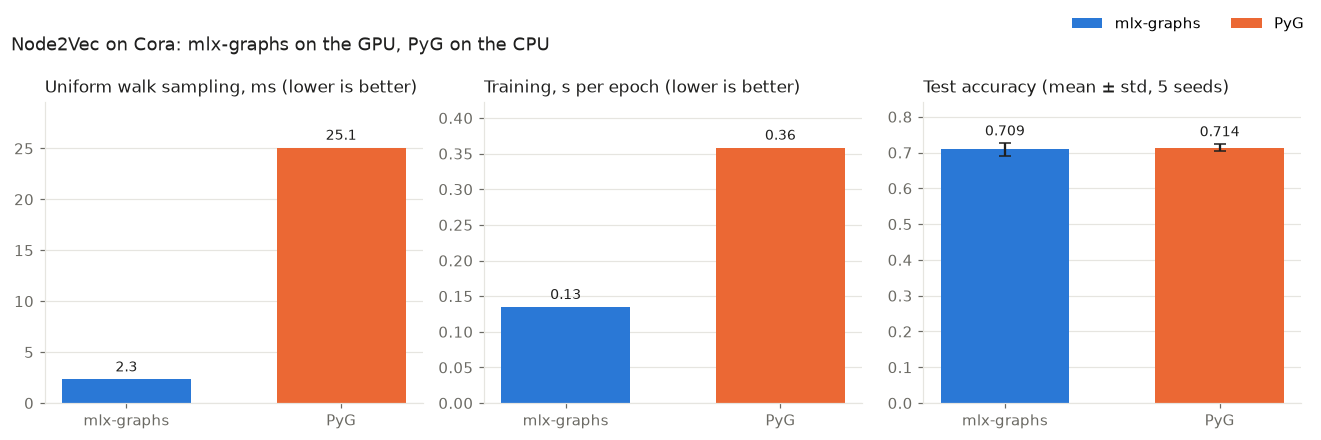

In [25]:
libraries = ["mlx-graphs", "PyG"]
colors = [MLX_COLOR, PYG_COLOR]
accuracy = {lib: [r["accuracy"] for r in runs[lib]] for lib in libraries}
panels = [
    (
        "Uniform walk sampling, ms (lower is better)",
        [sampling_ms["mlx-graphs uniform"], sampling_ms["PyG uniform"]],
        None,
        ".1f",
    ),
    (
        "Training, s per epoch (lower is better)",
        [epoch_seconds(lib) for lib in libraries],
        None,
        ".2f",
    ),
    (
        f"Test accuracy (mean ± std, {len(COMPARISON_SEEDS)} seeds)",
        [np.mean(accuracy[lib]) for lib in libraries],
        [np.std(accuracy[lib], ddof=1) for lib in libraries],
        ".3f",
    ),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
x = np.arange(len(libraries))
for ax, (title, values, errors, fmt) in zip(axes, panels):
    bars = ax.bar(
        x,
        values,
        0.6,
        color=colors,
        yerr=errors,
        ecolor=INK,
        capsize=4,
        label=libraries,
    )
    label_bars(ax, bars, values, errors, fmt)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xticks(x, libraries)
    ax.set_ylim(0, max(values) * 1.18)
    style_axis(ax)
fig.suptitle(
    "Node2Vec on Cora: mlx-graphs on the GPU, PyG on the CPU",
    x=0.01,
    ha="left",
    color=INK,
)
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="upper right",
    ncols=2,
    frameon=False,
    bbox_to_anchor=(1.0, 1.06),
)
fig.tight_layout()
plt.show()

**Quality.** Both libraries train the same model and reach the same test accuracy: the mean ± std ranges over the seeds overlap, and the differences between seeds of one library are as large as the difference between the two libraries. Their final losses are also close. The speed comparison is therefore made at equal quality.

**Speed.** These timings were measured on an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU. mlx-graphs samples walks and trains faster than PyG (see the speedups printed above). The gap is larger for the walks alone than for training, which also includes the embedding lookups, the loss and the optimizer. mlx-graphs also samples biased walks on the GPU, which PyG's sampler doesn't support.

Two caveats. Without `pyg-lib`, the PyG sampling time measures the PyTorch fallback above, not `pyg-lib`'s C++ sampler, so install `pyg-lib` for a comparison with PyG's own sampler. And timings vary from run to run and from machine to machine, so run the notebook on your own machine to compare.

## Going further

- Try other values of `p` and `q`, or a larger `embedding_dim` or more `walks_per_node`. Tune them on the validation split (`graph.val_mask`, or the validation graph of `RandomLinkSplit`), not on the test split.
- The same code runs on the other Planetoid graphs, `PlanetoidDataset("CiteSeer")` and `PlanetoidDataset("PubMed")`, or on any graph given as an `edge_index`.
- Node2Vec embeddings can be concatenated with the node features and fed to a GNN, for example a `GCNConv` model as in the other tutorials.
- For the details of the walk samplers, see the docstrings of `mlx_cluster.random_walk` and `mlx_cluster.rejection_sampling`.